# Logistic Regression — Online Shoppers Purchasing Intention
**IT2011 AI/ML — Model 1 (classification baseline)**

Goal: predict `Revenue` (1 = session ends in a purchase, ~15.6% of sessions).

Plan (follows the group *Model Training Guide*):
1. Load the group pipeline outputs and recover the **non-SMOTE** training set.
2. Train 8 varieties, compared with `StratifiedKFold(5, shuffle=True, random_state=42)` on the training set only.
3. Tuning metric: **F1 on the purchase class** (same for every variety). PR-AUC, ROC-AUC, precision and recall are also reported.
4. Pick the best variety by **CV F1**, then score the test set **once**, for that variety only.
5. Interpret coefficients as odds ratios and export a row per variety for the shared results table.

In [1]:
# CELL 1: Setup
# imbalanced-learn provides SMOTE + a Pipeline that only resamples the training part of each fold
%pip install -q imbalanced-learn

import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay,
                             precision_recall_curve, classification_report)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore', category=FutureWarning)   # sklearn 'penalty' deprecation notices
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'f1': 'f1', 'pr_auc': 'average_precision', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall'}
PRIMARY = 'f1'      # the single tuning metric used for every variety
print('Setup done')

Note: you may need to restart the kernel to use updated packages.
Setup done


## 1. Load data

Files from the group pipeline: `X_train_balanced`, `y_train_balanced`, `X_test_selected`, `y_test` (22 selected, scaled + encoded features).

**Recovering the non-SMOTE training set.** The guide says to train/tune on data *without* SMOTE, but only the SMOTE'd training file was shared. `imblearn`'s SMOTE returns the original rows first, in their original order, and appends the synthetic rows at the end. So the first 9,764 rows of `X_train_balanced` are exactly the original training set. The asserts below check this (class balance matches the test set, every synthetic row is class 1, and the one-hot columns of the recovered rows are all pure 0/1, which synthetic rows are not).

If a teammate shares `X_train_selected.csv` + `y_train.csv` directly, the cell uses those instead.

In [2]:
# CELL 2: Load files (works with names like 'X_test_selected (1).csv')
def find(prefix):
    hits = sorted(glob.glob(f'**/{prefix}*.csv', recursive=True))
    return hits[0] if hits else None

X_test  = pd.read_csv(find('X_test_selected'))
y_test  = pd.read_csv(find('y_test')).iloc[:, 0].astype(int)
X_bal   = pd.read_csv(find('X_train_balanced'))
y_bal   = pd.read_csv(find('y_train_balanced')).iloc[:, 0].astype(int)

if find('X_train_selected') and find('y_train'):
    X_train = pd.read_csv(find('X_train_selected'))
    y_train = pd.read_csv(find('y_train')).iloc[:, 0].astype(int)
    print('Using X_train_selected / y_train shared by the group')
else:
    N_ORIG = 9764                          # original (pre-SMOTE) training rows
    X_train = X_bal.iloc[:N_ORIG].reset_index(drop=True)
    y_train = y_bal.iloc[:N_ORIG].reset_index(drop=True)

    cat_cols = [c for c in X_bal.columns if c.startswith('categorical__')]
    assert (y_bal.iloc[N_ORIG:] == 1).all(), 'rows after N_ORIG should all be synthetic positives'
    assert X_train[cat_cols].isin([0, 1]).all().all(), 'recovered rows should have pure 0/1 one-hots'
    assert abs(y_train.mean() - y_test.mean()) < 0.005, 'class ratio should match the stratified test set'
    print('Recovered the original training set from the first rows of X_train_balanced')

assert list(X_train.columns) == list(X_test.columns)
print(f'Train: {X_train.shape}  purchase rate = {y_train.mean():.3f}')
print(f'Test : {X_test.shape}   purchase rate = {y_test.mean():.3f}')
print(f'Balanced (SMOTE) train: {X_bal.shape}  purchase rate = {y_bal.mean():.3f}')

# Shorter feature names for plots/tables
short = {c: c.replace('numerical__', '').replace('categorical__', '') for c in X_train.columns}
X_train = X_train.rename(columns=short); X_test = X_test.rename(columns=short); X_bal = X_bal.rename(columns=short)

Recovered the original training set from the first rows of X_train_balanced
Train: (9764, 22)  purchase rate = 0.156
Test : (2441, 22)   purchase rate = 0.156
Balanced (SMOTE) train: (16476, 22)  purchase rate = 0.500


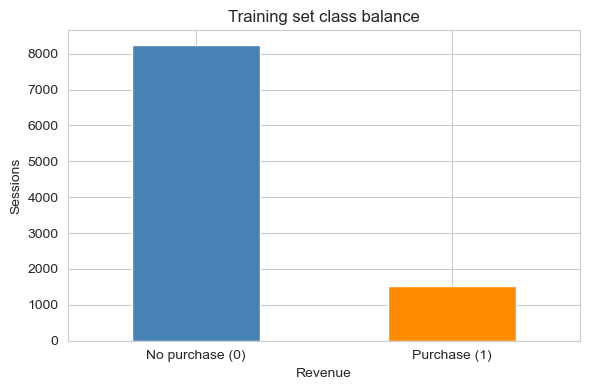

A model that always predicts "no purchase" gets 84.4% accuracy but F1 = 0.


In [3]:
# CELL 3: Class imbalance — why accuracy is misleading
fig, ax = plt.subplots(figsize=(6, 4))
y_train.value_counts().sort_index().plot.bar(ax=ax, color=['steelblue', 'darkorange'])
ax.set_xticklabels(['No purchase (0)', 'Purchase (1)'], rotation=0)
ax.set_title('Training set class balance'); ax.set_ylabel('Sessions')
plt.tight_layout(); plt.show()
print(f'A model that always predicts "no purchase" gets {1 - y_train.mean():.1%} accuracy but F1 = 0.')

## 2. Helper functions
`run_cv` cross-validates a model on the training set and records mean ± std of every metric, plus the **train** F1 so overfitting is visible (train F1 much higher than CV F1 = overfitting).

In [4]:
# CELL 4: CV helper + results log
results = []

def run_cv(name, model, X, y, params_text, note=''):
    cv = cross_validate(model, X, y, cv=CV, scoring=SCORING,
                        return_train_score=True, n_jobs=-1)
    row = {'Model': 'Logistic Regression', 'Variety': name, 'Key hyperparameters': params_text}
    for m in SCORING:
        row[f'CV {m}'] = cv[f'test_{m}'].mean()
        row[f'CV {m} std'] = cv[f'test_{m}'].std()
    row['Train f1'] = cv['train_f1'].mean()
    row['Note'] = note
    results.append(row)
    print(f"{name:<34s} CV F1 = {row['CV f1']:.4f} ± {row['CV f1 std']:.4f} | "
          f"PR-AUC = {row['CV pr_auc']:.4f} | recall = {row['CV recall']:.4f} | "
          f"precision = {row['CV precision']:.4f}")
    return row

def lr(**kw):
    base = dict(max_iter=5000, random_state=SEED)
    base.update(kw)
    return LogisticRegression(**base)

## 3. Varieties

| # | Variety | What changes |
|---|---|---|
| V1 | Default baseline | Nothing — `LogisticRegression()` defaults (C=1, L2, lbfgs) |
| V2 | class_weight = balanced | Errors on the purchase class cost ~5.4× more |
| V3 | SMOTE inside CV | Synthetic positives created only from each fold's training part |
| V4 | Tuned + class_weight | GridSearchCV over C, penalty, solver |
| V5 | Tuned + SMOTE-in-CV | Same grid, SMOTE inside the pipeline |
| V6 | L1 sparse model | Strong L1 penalty → automatic feature selection |
| V7 | Best + tuned threshold | Decision threshold chosen from out-of-fold probabilities |
| V8 | Trained on pre-SMOTE'd file | Comparison only — shows why resampling before CV is wrong |

In [5]:
# CELL 5: V1 — default baseline
run_cv('V1 Default baseline', lr(), X_train, y_train, 'C=1, l2, lbfgs, no weighting');

V1 Default baseline                CV F1 = 0.6213 ± 0.0188 | PR-AUC = 0.6862 | recall = 0.5511 | precision = 0.7140


In [6]:
# CELL 6: V2 — class_weight='balanced'
run_cv('V2 class_weight=balanced', lr(class_weight='balanced'), X_train, y_train,
       'C=1, l2, lbfgs, class_weight=balanced');

V2 class_weight=balanced           CV F1 = 0.6564 ± 0.0200 | PR-AUC = 0.6679 | recall = 0.7975 | precision = 0.5582


In [7]:
# CELL 7: V3 — SMOTE inside the CV pipeline (no leakage)
smote_pipe = ImbPipeline([('smote', SMOTE(random_state=SEED)), ('lr', lr())])
run_cv('V3 SMOTE-in-CV', smote_pipe, X_train, y_train, 'C=1, l2, lbfgs, SMOTE in each fold');

V3 SMOTE-in-CV                     CV F1 = 0.6530 ± 0.0160 | PR-AUC = 0.6672 | recall = 0.7981 | precision = 0.5535


### Hyperparameter grid
- **C** = inverse regularisation strength (small C = strong penalty = simpler model).
- **penalty**: L2 shrinks all coefficients; L1 can set some exactly to 0.
- **solver**: L1 needs `liblinear` or `saga`, so the grid is split into two dicts to avoid invalid combinations.

In [8]:
# CELL 8: V4 — GridSearchCV with class_weight='balanced'
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
grid_w = [
    {'penalty': ['l2'], 'solver': ['lbfgs', 'liblinear'], 'C': C_values},
    {'penalty': ['l1'], 'solver': ['liblinear', 'saga'],  'C': C_values},
]
gs_w = GridSearchCV(lr(class_weight='balanced'), grid_w, cv=CV, scoring=SCORING,
                    refit=PRIMARY, n_jobs=-1)
gs_w.fit(X_train, y_train)
print('Best params (class_weight):', gs_w.best_params_, f' CV F1 = {gs_w.best_score_:.4f}')

p = gs_w.best_params_
run_cv('V4 Tuned + class_weight', lr(class_weight='balanced', **p), X_train, y_train,
       f"C={p['C']}, {p['penalty']}, {p['solver']}, class_weight=balanced");

Best params (class_weight): {'C': 0.01, 'penalty': 'l1', 'solver': 'saga'}  CV F1 = 0.6693
V4 Tuned + class_weight            CV F1 = 0.6693 ± 0.0145 | PR-AUC = 0.6664 | recall = 0.7831 | precision = 0.5849


In [9]:
# CELL 9: V5 — GridSearchCV with SMOTE inside the pipeline
grid_s = [{f'lr__{k}': v for k, v in g.items()} for g in grid_w]
gs_s = GridSearchCV(ImbPipeline([('smote', SMOTE(random_state=SEED)), ('lr', lr())]),
                    grid_s, cv=CV, scoring=SCORING, refit=PRIMARY, n_jobs=-1)
gs_s.fit(X_train, y_train)
print('Best params (SMOTE):', gs_s.best_params_, f' CV F1 = {gs_s.best_score_:.4f}')

ps = {k.replace('lr__', ''): v for k, v in gs_s.best_params_.items()}
run_cv('V5 Tuned + SMOTE-in-CV',
       ImbPipeline([('smote', SMOTE(random_state=SEED)), ('lr', lr(**ps))]), X_train, y_train,
       f"C={ps['C']}, {ps['penalty']}, {ps['solver']}, SMOTE in each fold");

Best params (SMOTE): {'lr__C': 0.01, 'lr__penalty': 'l1', 'lr__solver': 'saga'}  CV F1 = 0.6698
V5 Tuned + SMOTE-in-CV             CV F1 = 0.6698 ± 0.0170 | PR-AUC = 0.6669 | recall = 0.7778 | precision = 0.5888


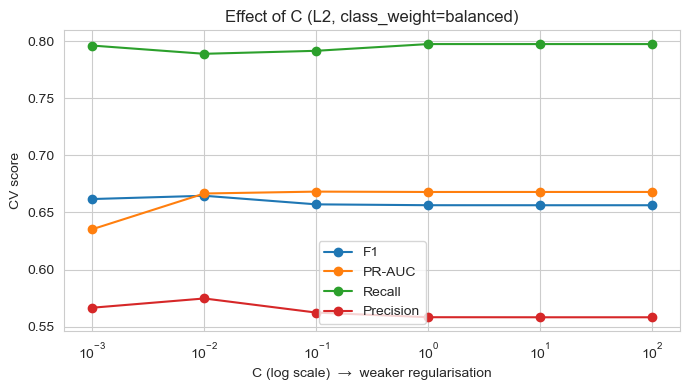

In [10]:
# CELL 10: Effect of C (from the class_weight grid, L2 + lbfgs rows)
cvres = pd.DataFrame(gs_w.cv_results_)
sub = cvres[(cvres.param_penalty == 'l2') & (cvres.param_solver == 'lbfgs')].sort_values('param_C')
fig, ax = plt.subplots(figsize=(7, 4))
for m, lab in [('f1', 'F1'), ('pr_auc', 'PR-AUC'), ('recall', 'Recall'), ('precision', 'Precision')]:
    ax.plot(sub.param_C.astype(float), sub[f'mean_test_{m}'], marker='o', label=lab)
ax.set_xscale('log'); ax.set_xlabel('C (log scale)  →  weaker regularisation'); ax.set_ylabel('CV score')
ax.set_title('Effect of C (L2, class_weight=balanced)'); ax.legend(); plt.tight_layout(); plt.show()

In [11]:
# CELL 11: V6 — L1 sparse model (strong penalty → feature selection)
v6 = lr(class_weight='balanced', penalty='l1', solver='liblinear', C=0.01)
run_cv('V6 L1 sparse (C=0.01)', v6, X_train, y_train, 'C=0.01, l1, liblinear, class_weight=balanced')
v6.fit(X_train, y_train)
kept = X_train.columns[v6.coef_[0] != 0]
print(f'L1 kept {len(kept)} of {X_train.shape[1]} features:', list(kept))

V6 L1 sparse (C=0.01)              CV F1 = 0.6681 ± 0.0143 | PR-AUC = 0.6743 | recall = 0.7877 | precision = 0.5806
L1 kept 8 of 22 features: ['PageValues', 'ExitRates', 'ProductRelated_Duration', 'BounceRates', 'Month_Nov', 'Informational', 'VisitorType_Returning_Visitor', 'Month_May']


### V7 — decision threshold tuning
Logistic regression outputs a probability; the default cut-off of 0.5 is arbitrary for imbalanced data. Using **out-of-fold** probabilities (each training row predicted by a model that never saw it), we pick the threshold that maximises F1. The test set is not touched.

*Caveat:* the threshold is chosen and scored on the same out-of-fold predictions, so V7's CV F1 is slightly optimistic.

Best so far by CV F1: V5 Tuned + SMOTE-in-CV
Best threshold = 0.568
V7 CV F1 = 0.6739 ± 0.0153 | precision = 0.6027 | recall = 0.7654


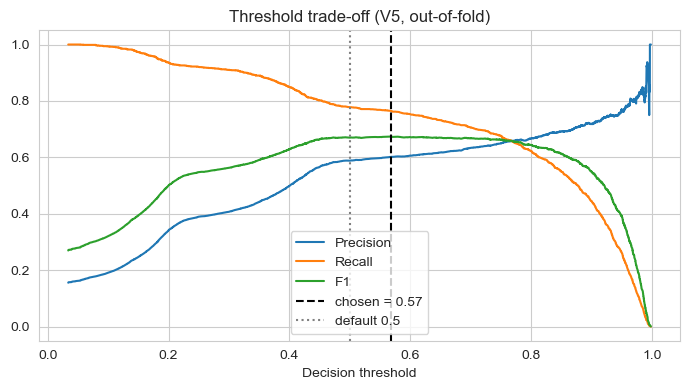

In [12]:
# CELL 12: V7 — best of V1–V6 + tuned threshold
candidates = {
    'V1 Default baseline': lr(),
    'V2 class_weight=balanced': lr(class_weight='balanced'),
    'V3 SMOTE-in-CV': smote_pipe,
    'V4 Tuned + class_weight': lr(class_weight='balanced', **p),
    'V5 Tuned + SMOTE-in-CV': ImbPipeline([('smote', SMOTE(random_state=SEED)), ('lr', lr(**ps))]),
    'V6 L1 sparse (C=0.01)': lr(class_weight='balanced', penalty='l1', solver='liblinear', C=0.01),
}
best_name = max([r for r in results if r['Variety'] in candidates], key=lambda r: r['CV f1'])['Variety']
base_model = candidates[best_name]
print('Best so far by CV F1:', best_name)

oof = cross_val_predict(base_model, X_train, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f1s)])
print(f'Best threshold = {best_thr:.3f}')

# Per-fold scores at the tuned threshold (same folds as every other variety)
fold_scores = {m: [] for m in SCORING}
for tr, va in CV.split(X_train, y_train):
    yv, pv = y_train.iloc[va], oof[va]
    pred = (pv >= best_thr).astype(int)
    fold_scores['f1'].append(f1_score(yv, pred))
    fold_scores['precision'].append(precision_score(yv, pred))
    fold_scores['recall'].append(recall_score(yv, pred))
    fold_scores['pr_auc'].append(average_precision_score(yv, pv))
    fold_scores['roc_auc'].append(roc_auc_score(yv, pv))
row = {'Model': 'Logistic Regression', 'Variety': 'V7 Best + tuned threshold',
       'Key hyperparameters': f'{best_name[:2]} settings, threshold={best_thr:.2f}'}
for m in SCORING:
    row[f'CV {m}'] = np.mean(fold_scores[m]); row[f'CV {m} std'] = np.std(fold_scores[m])
row['Train f1'] = np.nan
row['Note'] = 'threshold picked on OOF probs (slightly optimistic)'
results.append(row)
print(f"V7 CV F1 = {row['CV f1']:.4f} ± {row['CV f1 std']:.4f} | precision = {row['CV precision']:.4f} | recall = {row['CV recall']:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, prec[:-1], label='Precision'); ax.plot(thr, rec[:-1], label='Recall'); ax.plot(thr, f1s, label='F1')
ax.axvline(best_thr, ls='--', c='k', label=f'chosen = {best_thr:.2f}'); ax.axvline(0.5, ls=':', c='grey', label='default 0.5')
ax.set_xlabel('Decision threshold'); ax.set_title(f'Threshold trade-off ({best_name[:2]}, out-of-fold)'); ax.legend()
plt.tight_layout(); plt.show()

### V8 — comparison variety: model trained on the pre-SMOTE'd file
The guide says `X_train_balanced` must **not** be used for tuning or model selection. It is shown here only to demonstrate the problem: when SMOTE runs *before* the split, synthetic points built from a validation row's neighbours end up in the training folds, and half the validation data is synthetic. The CV score is therefore inflated and not comparable to V1–V7. Compare it with V3, the leak-free version of the same idea. **V8 is excluded from model selection.**

In [13]:
# CELL 13: V8 — CV on the pre-SMOTE'd data (illustration of leakage only)
run_cv('V8 Pre-SMOTE file (LEAKY)', lr(), X_bal, y_bal, 'C=1, l2, lbfgs, trained on X_train_balanced',
       note='Leaky CV, NOT used for selection')
v3 = next(r for r in results if r['Variety'].startswith('V3'))
v8 = results[-1]
print(f"\nV8 CV F1 (leaky) = {v8['CV f1']:.4f} vs V3 CV F1 (correct) = {v3['CV f1']:.4f}")
print('V8 is validated on a 50/50 synthetic-heavy set, so its score does not reflect the real 15% purchase rate.')

V8 Pre-SMOTE file (LEAKY)          CV F1 = 0.8390 ± 0.0043 | PR-AUC = 0.9048 | recall = 0.8093 | precision = 0.8710

V8 CV F1 (leaky) = 0.8390 vs V3 CV F1 (correct) = 0.6530
V8 is validated on a 50/50 synthetic-heavy set, so its score does not reflect the real 15% purchase rate.


## 4. Comparison of all varieties (CV on the training set)

,Variety,Key hyperparameters,CV f1,CV f1 std,CV pr_auc,CV roc_auc,CV precision,CV recall,Train f1,Note,Train−CV F1 gap
0,V1 Default baseline,"C=1, l2, lbfgs, no weighting",0.6213,0.0188,0.6862,0.9094,0.7140,0.5511,0.6228,,0.0014
1,V2 class_weight=balanced,"C=1, l2, lbfgs, class_weight=balanced",0.6564,0.0200,0.6679,0.9133,0.5582,0.7975,0.6593,,0.0029
2,V3 SMOTE-in-CV,"C=1, l2, lbfgs, SMOTE in each fold",0.6530,0.0160,0.6672,0.9117,0.5535,0.7981,0.6530,,-0.0001
3,V4 Tuned + class_weight,"C=0.01, l1, saga, class_weight=balanced",0.6693,0.0145,0.6664,0.9102,0.5849,0.7831,0.6696,,0.0003
4,V5 Tuned + SMOTE-in-CV,"C=0.01, l1, saga, SMOTE in each fold",0.6698,0.0170,0.6669,0.9123,0.5888,0.7778,0.6708,,0.0010
5,V6 L1 sparse (C=0.01),"C=0.01, l1, liblinear, class_weight=balanced",0.6681,0.0143,0.6743,0.9133,0.5806,0.7877,0.6701,,0.0020
6,V7 Best + tuned threshold,"V5 settings, threshold=0.57",0.6739,0.0153,0.6669,0.9123,0.6027,0.7654,NaN,threshold picked on OOF probs (slightly optimi...,NaN
7,V8 Pre-SMOTE file (LEAKY),"C=1, l2, lbfgs, trained on X_train_balanced",0.8390,0.0043,0.9048,0.9183,0.8710,0.8093,0.8391,"Leaky CV, NOT used for selection",0.0002


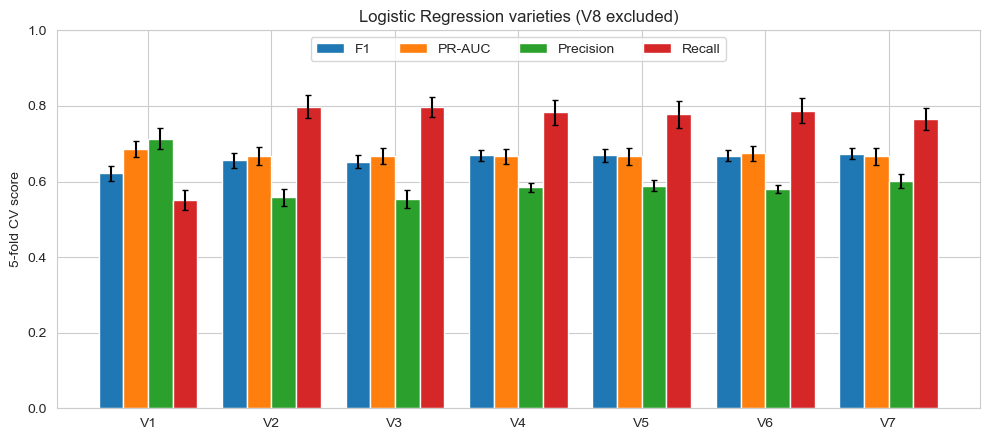

In [14]:
# CELL 14: Results table
res = pd.DataFrame(results)
show = res[['Variety', 'Key hyperparameters', 'CV f1', 'CV f1 std', 'CV pr_auc', 'CV roc_auc',
            'CV precision', 'CV recall', 'Train f1', 'Note']].copy()
show['Train−CV F1 gap'] = show['Train f1'] - show['CV f1']
display(show.round(4))

plot_df = res[~res.Variety.str.startswith('V8')]
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(plot_df)); w = 0.2
for i, (m, lab) in enumerate([('f1', 'F1'), ('pr_auc', 'PR-AUC'), ('precision', 'Precision'), ('recall', 'Recall')]):
    ax.bar(x + (i - 1.5) * w, plot_df[f'CV {m}'], w, label=lab,
           yerr=plot_df[f'CV {m} std'], capsize=2)
ax.set_xticks(x); ax.set_xticklabels([v.split(' ', 1)[0] for v in plot_df.Variety])
ax.set_ylim(0, 1); ax.set_ylabel('5-fold CV score'); ax.set_title('Logistic Regression varieties (V8 excluded)')
ax.legend(ncol=4, loc='upper center'); plt.tight_layout(); plt.show()

## 5. Final model → test set (scored once)
The final variety is the one with the highest **CV F1** among V1–V7. It is refit on the full training set and evaluated on the untouched test set.

In [15]:
# CELL 15: Select final variety and evaluate on the test set
selectable = res[~res.Variety.str.startswith('V8')]
final_name = selectable.loc[selectable['CV f1'].idxmax(), 'Variety']
use_thr = final_name.startswith('V7')
final_model = base_model if use_thr else candidates[final_name]
threshold = best_thr if use_thr else 0.5
print(f'Final variety: {final_name}  (threshold = {threshold:.2f})')

final_model.fit(X_train, y_train)
proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)

test_metrics = {
    'Test precision': precision_score(y_test, pred),
    'Test recall':    recall_score(y_test, pred),
    'Test F1':        f1_score(y_test, pred),
    'Test ROC-AUC':   roc_auc_score(y_test, proba),
    'Test PR-AUC':    average_precision_score(y_test, proba),
}
for k, v in test_metrics.items():
    print(f'{k:<15s} {v:.4f}')
print()
print(classification_report(y_test, pred, target_names=['No purchase', 'Purchase'], digits=4))

Final variety: V7 Best + tuned threshold  (threshold = 0.57)
Test precision  0.6113
Test recall     0.7618
Test F1         0.6783
Test ROC-AUC    0.9205
Test PR-AUC     0.6783

              precision    recall  f1-score   support

 No purchase     0.9537    0.9102    0.9314      2059
    Purchase     0.6113    0.7618    0.6783       382

    accuracy                         0.8869      2441
   macro avg     0.7825    0.8360    0.8049      2441
weighted avg     0.9001    0.8869    0.8918      2441



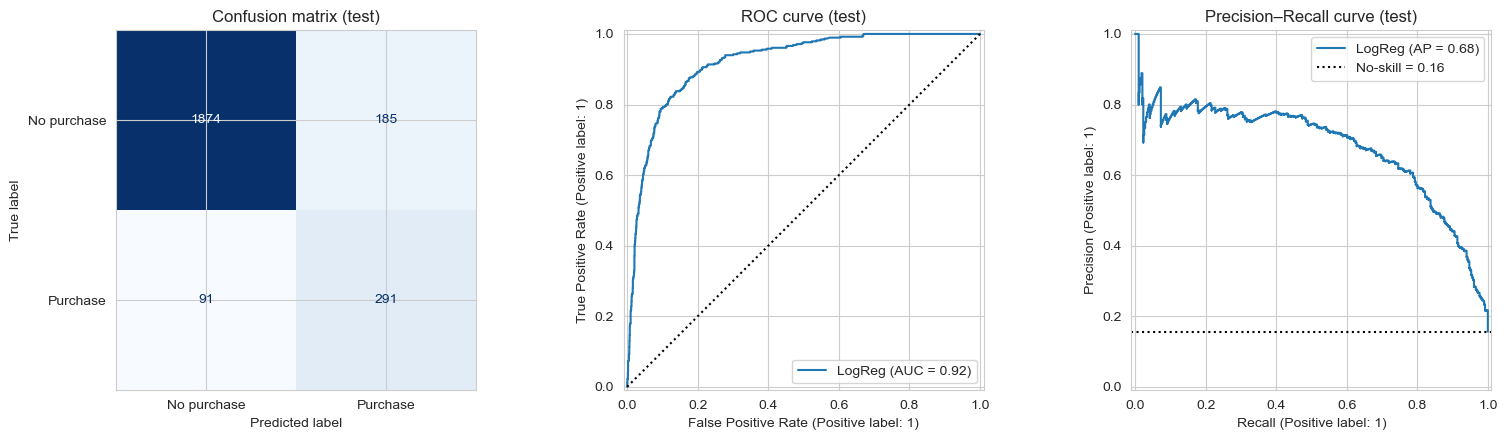

Caught 291 of 382 buyers; 185 false alarms among 2059 non-buyers.


In [16]:
# CELL 16: Confusion matrix, ROC and PR curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=['No purchase', 'Purchase']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion matrix (test)')
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name='LogReg')
axes[1].plot([0, 1], [0, 1], 'k:'); axes[1].set_title('ROC curve (test)')
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[2], name='LogReg')
axes[2].axhline(y_test.mean(), ls=':', c='k', label=f'No-skill = {y_test.mean():.2f}')
axes[2].legend(); axes[2].set_title('Precision–Recall curve (test)')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f'Caught {tp} of {tp + fn} buyers; {fp} false alarms among {tn + fp} non-buyers.')

## 6. Interpretation — coefficients and odds ratios
Odds ratio = e^coefficient. Above 1 raises the odds of a purchase, below 1 lowers them.
- **Numeric features** were transformed and standardised by the group pipeline, so their odds ratio is the change in purchase odds per **1 standard deviation** increase of the (transformed) feature.
- **One-hot features** (0/1) compare that category with the reference category (e.g. `Month_Nov` vs. the dropped month).

,Feature,Coefficient,Odds ratio
0,PageValues,1.4771,4.3802
1,Month_Nov,1.0912,2.9777
2,Month_May,-0.5181,0.5956
3,ExitRates,-0.2748,0.7597
4,BounceRates,-0.1687,0.8447
5,TrafficType_2,0.0861,1.0899
6,ProductRelated_Duration,0.0769,1.0799
7,VisitorType_Returning_Visitor,-0.0556,0.9459
8,Administrative,0.0072,1.0072
9,TrafficType_3,-0.0003,0.9997


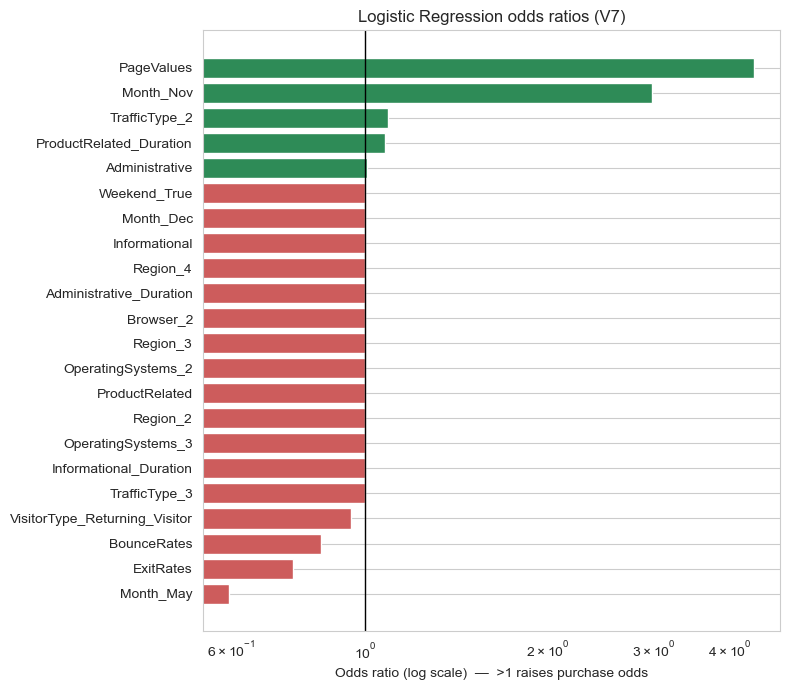

Strongest feature: PageValues — odds ratio 4.38


In [17]:
# CELL 17: Odds ratios of the final model
clf = final_model.named_steps['lr'] if hasattr(final_model, 'named_steps') else final_model
coef = pd.DataFrame({'Feature': X_train.columns, 'Coefficient': clf.coef_[0]})
coef['Odds ratio'] = np.exp(coef['Coefficient'])
coef = coef.reindex(coef['Coefficient'].abs().sort_values(ascending=False).index).reset_index(drop=True)
display(coef.round(4))

fig, ax = plt.subplots(figsize=(8, 7))
c = coef.sort_values('Coefficient')
ax.barh(c.Feature, c['Odds ratio'], color=np.where(c.Coefficient > 0, 'seagreen', 'indianred'))
ax.axvline(1, c='k', lw=1); ax.set_xscale('log')
ax.set_xlabel('Odds ratio (log scale)  —  >1 raises purchase odds')
ax.set_title(f'Logistic Regression odds ratios ({final_name.split(" ", 1)[0]})')
plt.tight_layout(); plt.show()

top = coef.iloc[0]
print(f"Strongest feature: {top.Feature} — odds ratio {top['Odds ratio']:.2f}")

## 7. Export rows for the shared results table

In [18]:
# CELL 18: One row per variety for the group table (test metrics only for the final variety)
shared = res[['Model', 'Variety', 'Key hyperparameters', 'CV f1', 'CV pr_auc', 'Note']].rename(
    columns={'CV f1': 'CV F1', 'CV pr_auc': 'CV PR-AUC'}).copy()
for k in test_metrics:
    shared[k] = np.nan
shared.loc[shared.Variety == final_name, list(test_metrics)] = list(test_metrics.values())
shared = shared.round(4)
display(shared)

os.makedirs('results/outputs', exist_ok=True)
shared.to_csv('results/outputs/logistic_regression_results.csv', index=False)
print('Saved results/outputs/logistic_regression_results.csv')

,Model,Variety,Key hyperparameters,CV F1,CV PR-AUC,Note,Test precision,Test recall,Test F1,Test ROC-AUC,Test PR-AUC
0,Logistic Regression,V1 Default baseline,"C=1, l2, lbfgs, no weighting",0.6213,0.6862,,NaN,NaN,NaN,NaN,NaN
1,Logistic Regression,V2 class_weight=balanced,"C=1, l2, lbfgs, class_weight=balanced",0.6564,0.6679,,NaN,NaN,NaN,NaN,NaN
2,Logistic Regression,V3 SMOTE-in-CV,"C=1, l2, lbfgs, SMOTE in each fold",0.6530,0.6672,,NaN,NaN,NaN,NaN,NaN
3,Logistic Regression,V4 Tuned + class_weight,"C=0.01, l1, saga, class_weight=balanced",0.6693,0.6664,,NaN,NaN,NaN,NaN,NaN
4,Logistic Regression,V5 Tuned + SMOTE-in-CV,"C=0.01, l1, saga, SMOTE in each fold",0.6698,0.6669,,NaN,NaN,NaN,NaN,NaN
5,Logistic Regression,V6 L1 sparse (C=0.01),"C=0.01, l1, liblinear, class_weight=balanced",0.6681,0.6743,,NaN,NaN,NaN,NaN,NaN
6,Logistic Regression,V7 Best + tuned threshold,"V5 settings, threshold=0.57",0.6739,0.6669,threshold picked on OOF probs (slightly optimi...,0.6113,0.7618,0.6783,0.9205,0.6783
7,Logistic Regression,V8 Pre-SMOTE file (LEAKY),"C=1, l2, lbfgs, trained on X_train_balanced",0.8390,0.9048,"Leaky CV, NOT used for selection",NaN,NaN,NaN,NaN,NaN


Saved results/outputs/logistic_regression_results.csv


## 8. Notes for the viva
- **Why logistic regression suits this data:** binary target, mostly numeric/one-hot features already scaled, and the coefficients are directly interpretable. It is the linear baseline the other five models are compared against.
- **Imbalance:** without weighting (V1) the model favours the majority class, so recall is low. Class weights or SMOTE-in-CV trade some precision for much higher recall.
- **Validation:** stratified 5-fold CV on the training set only; resampling happens inside each fold; the test set is scored once.
- **Overfitting:** compare `Train f1` with `CV f1` — a small gap is expected for a regularised linear model.
- **Limitations:** assumes a linear relationship between features and the log-odds, so interactions (e.g. PageValues × Month) are missed unless engineered; tree ensembles may capture these. Only the 22 selected features were available — comparing with all features would need the group's `X_train_processed` file.